# FairFace dataset exploration

Which apparent-age groups have the most images, and where are examples scarce? This notebook uses the 86,744 images in the publisher’s training split before exclusions. The publisher’s 10,954-image validation split is reserved for the final holdout.

Run the cells in order using the [notebook setup](README.md). The default run reads published aggregate counts. Set `EXPLORE_RAW_DATA = True` to inspect local labels and image examples. Keep raw-data outputs private. `SAVE_OUTPUTS` is off by default.

Data source: [Kärkkäinen and Joo, FairFace (WACV 2021)](https://github.com/joojs/fairface), CC BY 4.0. The labels describe apparent age and annotated race.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as DisplayImage, display
from PIL import Image
from fairage.data import AGE_CLASSES, RACE_GROUPS

ROOT = Path.cwd()
while not (ROOT / "configs/baseline.yaml").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the project checkout.")
    ROOT = ROOT.parent
DATA = ROOT / "data/raw/fairface-padding-0.25"
PUBLISHED = ROOT / "results/published"
OUTPUT = ROOT / "results/simplified/eda"
EXPLORE_RAW_DATA = False
SAVE_OUTPUTS = False
if SAVE_OUTPUTS:
    OUTPUT.mkdir(parents=True, exist_ok=True)
age_order = AGE_CLASSES
race_order = RACE_GROUPS
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Python:", sys.version.split()[0])
print("Raw-data exploration:", EXPLORE_RAW_DATA)
print("Save outputs:", SAVE_OUTPUTS)
print("Optional exports: results/simplified/eda/")

Python: 3.12.16
Raw-data exploration: False
Save outputs: False
Optional exports: results/simplified/eda/


### Saved raw-data analysis

With raw-data mode on, this section can read local tables and figures from the earlier analysis.


In [2]:
REFERENCE = ROOT / "results/reference-eda"
if EXPLORE_RAW_DATA and REFERENCE.is_dir():
    for name in ("age_distribution.csv", "race_distribution.csv", "age_race_counts.csv"):
        path = REFERENCE / name
        if path.is_file():
            print(name)
            display(pd.read_csv(path))
    for name in ("fig_02_age_distribution.png", "fig_03_race_distribution.png",
                 "fig_04_age_race_heatmap.png", "fig_05_age_within_race_percent.png"):
        path = REFERENCE / name
        if path.is_file():
            display(DisplayImage(filename=str(path)))
else:
    print("Historical private EDA is not loaded in the default public workflow.")


Historical private EDA is not loaded in the default public workflow.


The notebook uses the shared class order. Charts display `Latino_Hispanic` as `Latino/Hispanic`.


## 2. Dataset overview

The public table has one row per population, age category, and annotated racial group. Age is the prediction target.


In [3]:
dataset_counts = pd.read_csv(PUBLISHED / "dataset_counts.csv")
publisher_counts = dataset_counts[dataset_counts.population == "publisher_training"].copy()
population_size = int(publisher_counts.support.sum())
display(publisher_counts.head())
print("Publisher-training images represented:", f"{population_size:,}")
print("Aggregate age/race cells:", len(publisher_counts))

train = None
if EXPLORE_RAW_DATA:
    train = pd.read_csv(DATA / "fairface_label_train.csv")
    print("Shape:", train.shape)
    print("Columns:", train.columns.tolist())
    train.info()
    display(train.head())
    display(train[["age", "gender", "race"]].describe())
    print("Age class order:", age_order)
    print("Demographic category order:", race_order)

    population_size = len(train)
else:
    print("Individual-record fields and data-quality checks are unavailable from aggregate counts.")


,population,race,age,support
0,publisher_training,East Asian,0-2,408
1,publisher_training,East Asian,3-9,1736
2,publisher_training,East Asian,10-19,1176
3,publisher_training,East Asian,20-29,4765
4,publisher_training,East Asian,30-39,2382


Publisher-training images represented: 86,744
Aggregate age/race cells: 63
Individual-record fields and data-quality checks are unavailable from aggregate counts.


The 86,744 images span all 63 age-by-race combinations.

### 2.1. Example training images

Raw-data mode shows the first filename from each of six selected age groups.


In [4]:
if EXPLORE_RAW_DATA:
    example_ages = ["0-2", "10-19", "20-29", "40-49", "60-69", "more than 70"]
    examples = (train.sort_values("file").drop_duplicates("age")
                .set_index("age").loc[example_ages])
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    for ax, (age, row) in zip(axes.flat, examples.iterrows()):
        with Image.open(DATA / "images" / row["file"]) as image:
            ax.imshow(np.asarray(image))
        ax.set_title(f"Apparent age label: {age}", fontsize=10)
        ax.axis("off")
    fig.suptitle("Figure 1. Illustrative training images — private research material")
    fig.tight_layout()
    if SAVE_OUTPUTS:
        fig.savefig(OUTPUT / "fig_01_representative_training_images.png", bbox_inches="tight")
    plt.show()
else:
    print("Private image examples are disabled; enable EXPLORE_RAW_DATA only with separately acquired FairFace.")


Private image examples are disabled; enable EXPLORE_RAW_DATA only with separately acquired FairFace.


**Figure 1.** Six training crops with their apparent-age labels. Keep the grid and its notebook output private.


## 3. Age distribution

Count the images in each age category and calculate their share of the publisher’s training split.


In [5]:
age_counts = (train["age"].value_counts() if EXPLORE_RAW_DATA
              else publisher_counts.groupby("age").support.sum())
age_table = age_counts.reindex(age_order).rename("count").to_frame()
age_table["percent"] = age_table["count"] / population_size * 100
age_table.index.name = "age"
if SAVE_OUTPUTS:
    age_table.to_csv(OUTPUT / "age_distribution.csv")
display(age_table.round({"percent": 2}))

,count,percent
age,,
0-2,1792,2.07
3-9,10408,12.00
10-19,9103,10.49
20-29,25598,29.51
30-39,19250,22.19
40-49,10744,12.39
50-59,6228,7.18
60-69,2779,3.20
more than 70,842,0.97


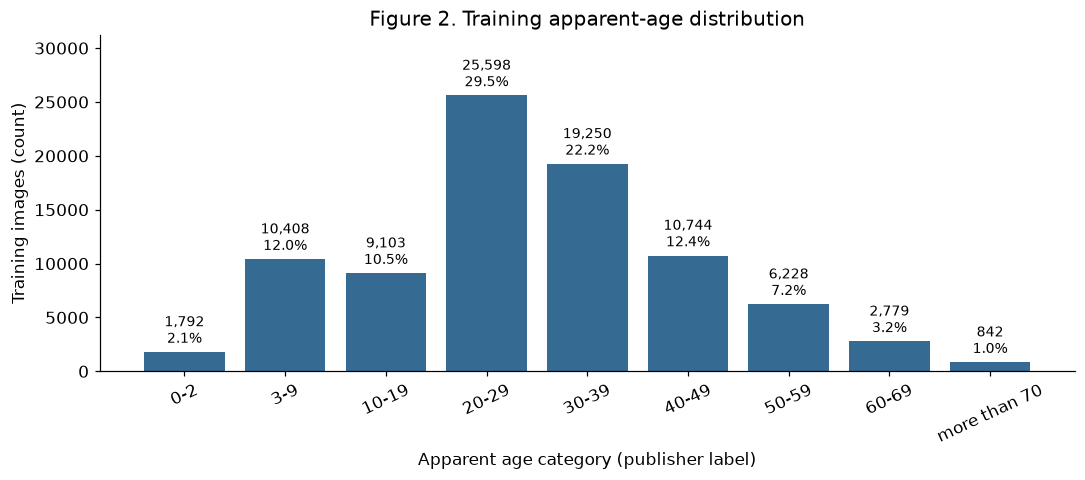

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(age_order, age_table["count"], color="#356A92")
ax.bar_label(bars, labels=[f"{n:,}\n{p:.1f}%" for n, p in age_table.itertuples(index=False)],
             padding=3, fontsize=9)
ax.set(title="Figure 2. Training apparent-age distribution",
       xlabel="Apparent age category (publisher label)", ylabel="Training images (count)")
ax.set_ylim(0, age_table["count"].max() * 1.22)
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
if SAVE_OUTPUTS:
    fig.savefig(OUTPUT / "fig_02_age_distribution.png", bbox_inches="tight")
plt.show()

**Figure 2.** Ages 20–29 and 30–39 make up 51.70% of the publisher’s training split. The oldest category has 842 images (0.97%). This imbalance is why the study reports macro-F1 alongside accuracy.


## 4. Distribution by annotated race


,count,percent
race,,
East Asian,12287,14.16
Indian,12319,14.20
Black,12233,14.10
White,16527,19.05
Middle Eastern,9216,10.62
Latino_Hispanic,13367,15.41
Southeast Asian,10795,12.44


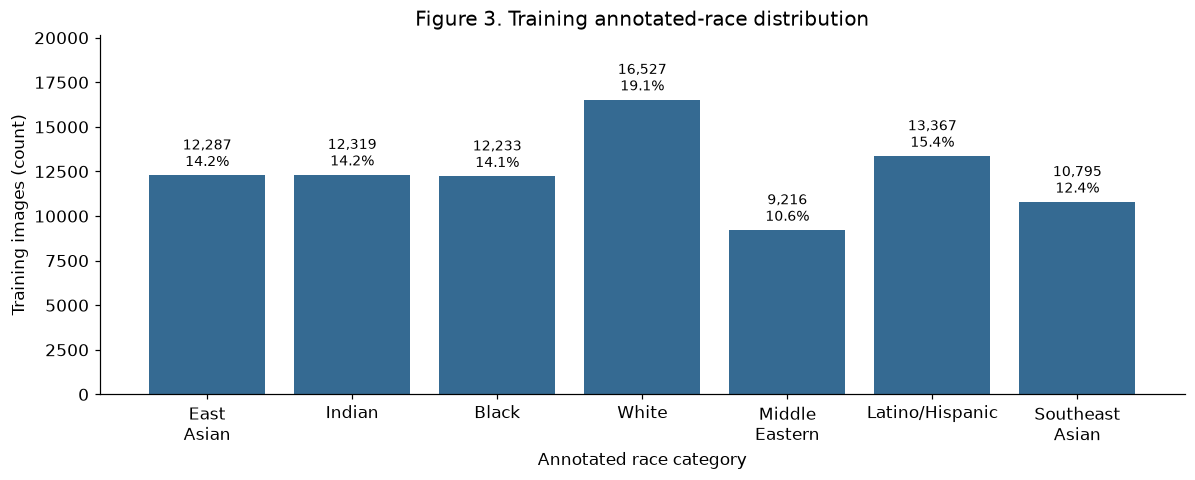

In [7]:
race_counts = (train["race"].value_counts() if EXPLORE_RAW_DATA
               else publisher_counts.groupby("race").support.sum())
race_table = race_counts.reindex(race_order).rename("count").to_frame()
race_table["percent"] = race_table["count"] / population_size * 100
race_table.index.name = "race"
if SAVE_OUTPUTS:
    race_table.to_csv(OUTPUT / "race_distribution.csv")
display(race_table.round({"percent": 2}))

race_ticks = [name.replace("Latino_Hispanic", "Latino/Hispanic").replace(" ", "\n")
              for name in race_order]
fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(race_ticks, race_table["count"], color="#356A92")
ax.bar_label(bars, labels=[f"{n:,}\n{p:.1f}%" for n, p in race_table.itertuples(index=False)],
             padding=3, fontsize=9)
ax.set(title="Figure 3. Training annotated-race distribution",
       xlabel="Annotated race category", ylabel="Training images (count)")
ax.set_ylim(0, race_table["count"].max() * 1.22)
fig.tight_layout()
if SAVE_OUTPUTS:
    fig.savefig(OUTPUT / "fig_03_race_distribution.png", bbox_inches="tight")
plt.show()

**Figure 3.** The largest group has 16,527 images and the smallest has 9,216. The largest age category has about 30 times as many images as the smallest.


## 5. Age by race

Use counts to check which age-by-race groups have few examples. Use column percentages to compare age distributions within racial groups.


In [8]:
age_race = (pd.crosstab(train["age"], train["race"]) if EXPLORE_RAW_DATA
            else publisher_counts.pivot(index="age", columns="race", values="support"))
age_race = age_race.reindex(index=age_order, columns=race_order)
if age_race.isna().any().any() or int(age_race.to_numpy().sum()) != population_size:
    raise ValueError("Incomplete publisher-training aggregate counts")
within_race = age_race.div(age_race.sum(axis=0), axis="columns") * 100
if SAVE_OUTPUTS:
    age_race.to_csv(OUTPUT / "age_race_counts.csv")
    within_race.to_csv(OUTPUT / "age_race_within_race_percent.csv")
display(age_race)

race,East Asian,Indian,Black,White,Middle Eastern,Latino_Hispanic,Southeast Asian
age,,,,,,,
0-2,408,169,279,399,134,189,214
3-9,1736,1530,2072,1237,721,1589,1523
10-19,1176,1529,1518,1148,735,1609,1388
20-29,4765,3077,3171,5221,2323,3531,3510
30-39,2382,2771,2619,4139,2398,2932,2009
40-49,939,1635,1459,2179,1517,1957,1058
50-59,524,984,764,1379,837,1124,616
60-69,270,457,279,676,435,355,307
more than 70,87,167,72,149,116,81,170


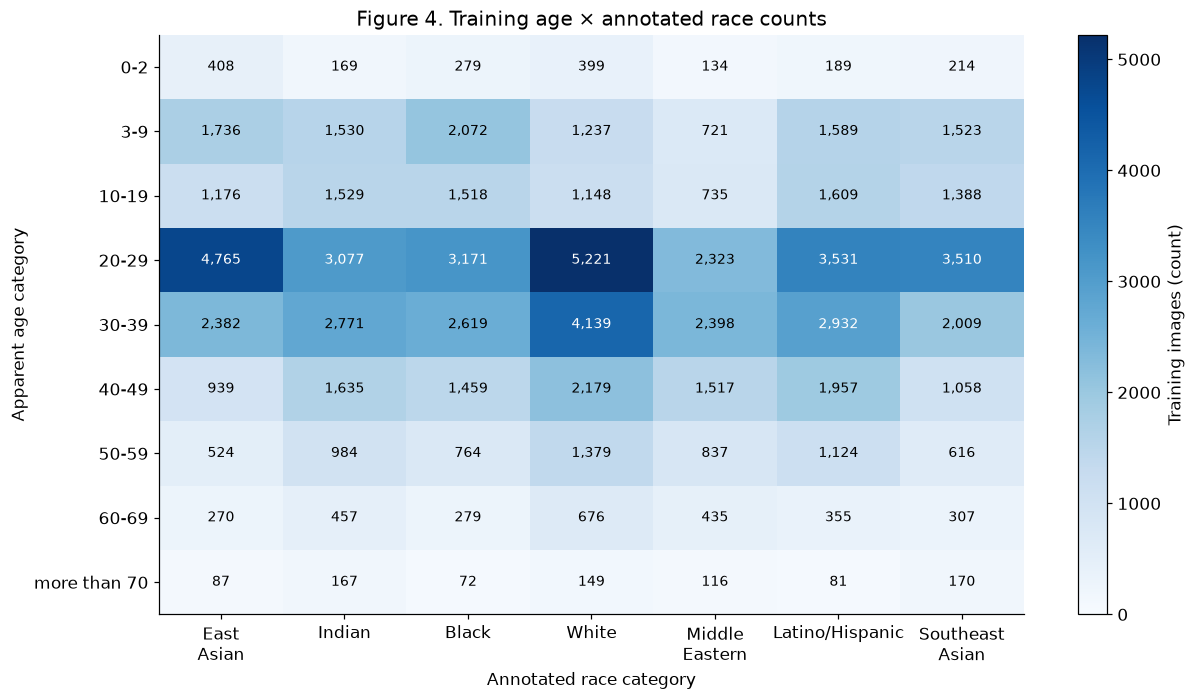

In [9]:
fig, ax = plt.subplots(figsize=(11.5, 6.5))
heat = ax.imshow(age_race.to_numpy(), cmap="Blues", vmin=0, aspect="auto")
for i, age in enumerate(age_order):
    for j, race in enumerate(race_order):
        count = age_race.loc[age, race]
        ax.text(j, i, f"{count:,}", ha="center", va="center", fontsize=9,
                color="white" if count > age_race.to_numpy().max() * 0.55 else "black")
ax.set_xticks(range(len(race_order)), race_ticks)
ax.set_yticks(range(len(age_order)), age_order)
ax.set(title="Figure 4. Training age × annotated race counts",
       xlabel="Annotated race category", ylabel="Apparent age category")
fig.colorbar(heat, ax=ax, label="Training images (count)")
fig.tight_layout()
if SAVE_OUTPUTS:
    fig.savefig(OUTPUT / "fig_04_age_race_heatmap.png", bbox_inches="tight")
plt.show()

**Figure 4.** Image counts range from 72 in the oldest Black group to 5,221 in the White 20–29 group.


race,East Asian,Indian,Black,White,Middle Eastern,Latino_Hispanic,Southeast Asian
age,,,,,,,
0-2,3.32,1.37,2.28,2.41,1.45,1.41,1.98
3-9,14.13,12.42,16.94,7.48,7.82,11.89,14.11
10-19,9.57,12.41,12.41,6.95,7.98,12.04,12.86
20-29,38.78,24.98,25.92,31.59,25.21,26.42,32.52
30-39,19.39,22.49,21.41,25.04,26.02,21.93,18.61
40-49,7.64,13.27,11.93,13.18,16.46,14.64,9.80
50-59,4.26,7.99,6.25,8.34,9.08,8.41,5.71
60-69,2.20,3.71,2.28,4.09,4.72,2.66,2.84
more than 70,0.71,1.36,0.59,0.90,1.26,0.61,1.57


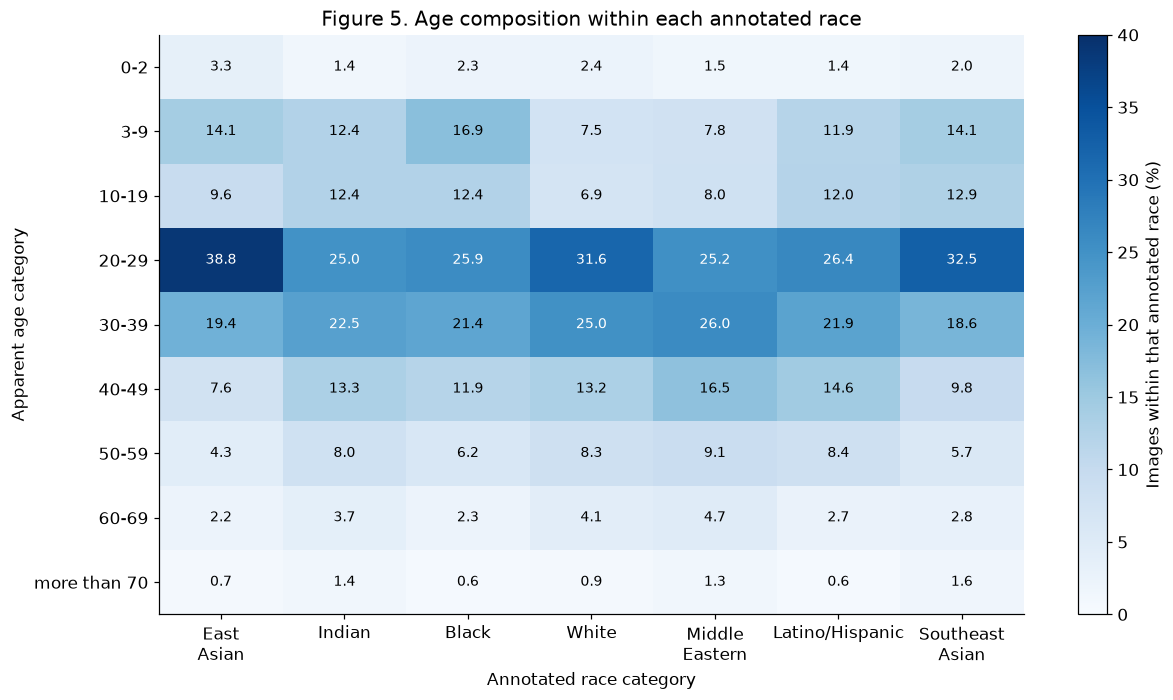

In [10]:
display(within_race.round(2))
fig, ax = plt.subplots(figsize=(11.5, 6.5))
heat = ax.imshow(within_race.to_numpy(), cmap="Blues", vmin=0, vmax=40, aspect="auto")
for i, age in enumerate(age_order):
    for j, race in enumerate(race_order):
        percent = within_race.loc[age, race]
        ax.text(j, i, f"{percent:.1f}", ha="center", va="center", fontsize=9,
                color="white" if percent > 22 else "black")
ax.set_xticks(range(len(race_order)), race_ticks)
ax.set_yticks(range(len(age_order)), age_order)
ax.set(title="Figure 5. Age composition within each annotated race",
       xlabel="Annotated race category", ylabel="Apparent age category")
fig.colorbar(heat, ax=ax, label="Images within that annotated race (%)")
fig.tight_layout()
if SAVE_OUTPUTS:
    fig.savefig(OUTPUT / "fig_05_age_within_race_percent.png", bbox_inches="tight")
plt.show()

**Figure 5.** Each column sums to 100%. For example, ages 20–29 make up 38.78% of the East Asian group and 24.98% of the Indian group.


In [11]:
cells_by_support = age_race.stack().rename("count").reset_index()
sparse_cells = cells_by_support[cells_by_support["count"] < 100].sort_values("count")
if SAVE_OUTPUTS:
    sparse_cells.to_csv(OUTPUT / "sparse_age_race_cells.csv", index=False)
display(sparse_cells)
print("Zero-support cells:", int((age_race == 0).sum().sum()))
print("Cells below 100:", len(sparse_cells))
print("Cells below 200:", int((age_race < 200).sum().sum()))

,age,race,count
58,more than 70,Black,72
61,more than 70,Latino_Hispanic,81
56,more than 70,East Asian,87


Zero-support cells: 0
Cells below 100: 3
Cells below 200: 10


Three cells have fewer than 100 images. All three are in the oldest age category.


## 6. Data quality

Raw-data mode checks missing labels and repeated filenames. Exact-image checks use a local hash inventory when available.


In [12]:
if EXPLORE_RAW_DATA:
    display(train.isna().sum().to_frame("missing_values"))
    print("Duplicate filename entries:", int(train["file"].duplicated().sum()))

else:
    print("Record-level missing-value and duplicate-filename checks require the publisher labels.")


Record-level missing-value and duplicate-filename checks require the publisher labels.


The original training CSV had no missing values or repeated filenames.

### 6.1. Duplicate images and conflicting labels


In [13]:
inventory_path = DATA / "provenance/image-integrity.csv"
duplicate_summary = None
if EXPLORE_RAW_DATA and inventory_path.is_file():
    image_hashes = pd.read_csv(inventory_path, usecols=["file", "sha256"])
    training_hashes = train.merge(image_hashes, on="file")
    duplicate_records = (training_hashes[training_hashes.duplicated("sha256", keep=False)]
                         .sort_values(["sha256", "file"]))
    duplicate_groups = duplicate_records.groupby("sha256").agg(
        images=("file", "size"), age_labels=("age", "nunique"),
        race_labels=("race", "nunique"), gender_labels=("gender", "nunique"),
    )
    if SAVE_OUTPUTS:
        duplicate_groups.to_csv(OUTPUT / "duplicate_training_groups.csv")
        duplicate_records.to_csv(OUTPUT / "duplicate_training_records.csv", index=False)
    duplicate_summary = pd.Series({
        "duplicate_groups": len(duplicate_groups), "images_in_duplicate_groups": len(duplicate_records),
        "copies_beyond_one_per_hash": len(duplicate_records) - len(duplicate_groups),
        "groups_with_conflicting_age": int((duplicate_groups["age_labels"] > 1).sum()),
        "groups_with_conflicting_race": int((duplicate_groups["race_labels"] > 1).sum()),
        "groups_with_conflicting_gender": int((duplicate_groups["gender_labels"] > 1).sum()),
    })
    display(duplicate_summary.to_frame("count"))

    conflicting_hashes = duplicate_groups.index[duplicate_groups["age_labels"] > 1][:3]
    conflict_examples = duplicate_records[duplicate_records["sha256"].isin(conflicting_hashes)].copy()
    conflict_examples["duplicate_group"] = conflict_examples.groupby("sha256").ngroup() + 1
    print("Examples of age-label conflicts within the same image-hash group:")
    display(conflict_examples[["duplicate_group", "age", "race", "gender"]].reset_index(drop=True))
else:
    print("Image-hash analysis is optional and unavailable from the public aggregate counts.")


Image-hash analysis is optional and unavailable from the public aggregate counts.


The later split excluded 273 records from training duplicate groups and 21 additional training records matching holdout hashes. The remaining records split into 77,805 training and 8,645 development images. The hash check covers exact matches. Near-duplicates and shared identities can remain.


## 7. Sampling

All baseline runs used shuffled batches and unweighted cross-entropy.


In [14]:
sampling_evidence = pd.Series({
    "largest_to_smallest_age_ratio": age_table["count"].max() / age_table["count"].min(),
    "age_20_39_percent": age_table.loc[["20-29", "30-39"], "percent"].sum(),
    "largest_to_smallest_race_ratio": race_table["count"].max() / race_table["count"].min(),
    "age_race_cells_below_100": len(sparse_cells),
})
if duplicate_summary is not None:
    sampling_evidence["duplicate_groups_with_age_conflicts"] = duplicate_summary["groups_with_conflicting_age"]
if SAVE_OUTPUTS:
    sampling_evidence.to_csv(OUTPUT / "sampling_assessment_inputs.csv", header=["value"])
display(sampling_evidence.round(3).to_frame("value"))


,value
largest_to_smallest_age_ratio,30.401
age_20_39_percent,51.702
largest_to_smallest_race_ratio,1.793
age_race_cells_below_100,3.000


Rare ages appear less often in shuffled batches. Age weighting or resampling could be tested in a separate experiment on the development set.


## 8. Summary


The age imbalance motivated macro-F1 and a closer look at errors by age. The sparse age-by-race groups also make it important to report image counts alongside results.

Optional exports go to `results/simplified/eda/`. Continue with the [model walkthrough](02_vit_math_walkthrough.ipynb) or [results](03_results_analysis.ipynb).
